# Joint MMR–ERT inversion with blocky regularization

The MMR data of `example_mmr.ipynb` and the surface ERT data of `example_dc.ipynb` are inverted together for a
single conductivity model.  The two methods are complementary.  The voltages give the absolute value of the
conductivity, but their sensitivity decreases quickly with depth.  The magnetic field only sees contrasts, but
it is sensitive to current channelling at depth.

`Inversion.run` takes the two data sets (`data_mmr` and `data_ert`) with a `GridMMR`.  With the default
`data_weighting = 'variance'`, each datum is weighted by the inverse of its error: `wt` % of the datum plus a
floor `Inversion.e` (0.1 pT or mV).  With `'variance*jacobian'` or `'variance+jacobian'`, the data are also
weighted with the norm of their sensitivity, and the MMR and ERT parts are scaled to the same median weight, so
that neither data set dominates because of its units or its number of data.

The data and the parameters are those of `example_joint.ipynb`, except for the regularization:
`smooth_type = 'blocky'` uses an $L_1$ measure of the model gradient (iteratively reweighted least squares).
It gives piecewise constant models with sharper edges than the default $L_2$ smoothness.  See
`example_dc25_regularization.ipynb` for a comparison of the regularizations.

**Prerequisites:** this notebook inverts data written by other notebooks.  Run them first:

- `example_mmr.ipynb` writes the MMR data, `data_mmr.dat`;
- `example_dc.ipynb` (or `example_dc_bicgstab.ipynb`) writes the ERT data, `data_dc_surf.dat`.

In [1]:
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy.sparse.linalg import bicgstab

sys.path.insert(0, os.path.abspath('..'))   # notebook run from the examples directory

from pymmr.finite_volume import calc_padding, GridFV
from pymmr.mmr import GridMMR
from pymmr.inversion import Inversion, df_to_data, DataMMR, DataERT

In [2]:
# data files written by other notebooks
for fname, nb in (("data_mmr.dat", "example_mmr.ipynb"), ("data_dc_surf.dat", "example_dc.ipynb")):
    if not os.path.isfile(fname):
        raise FileNotFoundError(f"{fname} not found: run {nb} first")

## Grid

The grid of `example_mmr.ipynb`: 60 m cells, 10 padding cells, air layers added by `GridMMR`.  The ERT data are
modelled with the `GridDC` of the MMR grid (`g.dc`).  The right-hand sides (one per source) are solved on
`n_threads` threads; this needs a free-threaded Python to run in parallel.

In [3]:
x = np.arange(-60.0*16, 60.01*16, 60)
y = np.arange(-60.0*16, 60.01*16, 60)
z = np.arange(-60.0*16, 0.01, 60)

pad = np.cumsum(calc_padding(60.0, 10))

x = np.r_[x[0] - pad[::-1], x, x[-1] + pad]
y = np.r_[y[0] - pad[::-1], y, y[-1] + pad]
z = np.r_[z[0] - pad, z]

n_threads = 12
g = GridMMR((x, y, z), n_threads=n_threads)
g.set_solver('mumps')
# g.set_solver(bicgstab)
g.verbose = False

## Data

The files are read with pandas, and `df_to_data` builds a `DataMMR` or a `DataERT` according to the columns.
Only the surface ERT dipoles are used, which matches an MMR survey with surface magnetometers.  The commented
lines show how to read files in another format.

In [4]:
# tmp = np.loadtxt('data_mmr_j.dat', comments='%')
# for col in (5, 11):
#     tmp[:, col] = -tmp[:, col]  # convert to elevation
# data_mmr = DataMMR(xs=tmp[:, 3:9], xo=tmp[:, 9:12], data=tmp[:, :3], wt=np.ones((3*tmp.shape[0],)),
#                    cs=np.ones((tmp.shape[0],)), date=None)
#
# tmp = np.loadtxt('data_ert_j.dat', comments='%')
# for col in (2, 5, 8, 11):
#     tmp[:, col] = -tmp[:, col]  # convert to elevation
# data_ert = DataERT(c1c2=tmp[:, :6], p1p2=tmp[:, 6:12], data=1000*tmp[:, 12], wt=np.ones((tmp.shape[0],)),
#                    cs=np.ones((tmp.shape[0],)), date=None)

df_mmr = pd.read_table("data_mmr.dat", sep="\\s+", escapechar="#")
df_mmr.columns = df_mmr.columns.str.replace(" ", "")  # remove spaces in keys
data_mmr = df_to_data(df_mmr)

df_ert = pd.read_table("data_dc_surf.dat", sep="\\s+", escapechar="#")
df_ert.columns = df_ert.columns.str.replace(" ", "")
data_ert = df_to_data(df_ert)

/var/folders/my/mlz8ktrs16g2gy8xqqnyqb880000gn/T/ipykernel_26490/445488235.py:15: UserWarning: MMR measurement error not defined, using 1%
  data_mmr = df_to_data(df_mmr)
/var/folders/my/mlz8ktrs16g2gy8xqqnyqb880000gn/T/ipykernel_26490/445488235.py:19: UserWarning: ERT measurement error not defined, using 1%
  data_ert = df_to_data(df_ert)


## Inversion

Gauss-Newton inversion for $\ln\sigma$:

- starting and reference model: the 1000 Ω·m half-space;
- smoothness weights `alx`, `aly`, `alz` = 0.5;
- $\beta$ from 2500, divided by 2 at each iteration down to 100;
- 5 iterations;
- only the cells of the region of interest are inverted.
- `smooth_type = 'blocky'`.

The models of the iterations are written to `example_joint_blocky.vtr`.  Compare them with `example_mmr.vtr`
(MMR only), `example_dc.vtr` (ERT, surface and boreholes) and `m_true.vtr`.


Inversion
    Grid: 52 x 52 x 26 voxels
      X min: -4.284321e+03	X max: 4.284321e+03
      Y min: -4.284321e+03	Y max: 4.284321e+03
      Z min: -4.284321e+03	Z max: 0.000000e+00
    Region of interest:
      X min: -4.000000e+02	X max: 4.000000e+02
      Y min: -4.000000e+02	Y max: 4.000000e+02
      Z min: -9.600000e+02	Z max: 0.000000e+00
    Number of parameters to estimate: 3136
    Number of MMR data: 4047
    Number of ERT data: 5096
    Algorithm: Gauss-Newton
    Maximum number of iterations: 5
    Working variable: log_conductivity
    Type of smoothing: blocky
      Smoothing factor along x: 0.5
      Smoothing factor along y: 0.5
      Smoothing factor along z: 0.5
      Smallness factor: 0.01
    Regularization variable: model
    Regularization β: 2500
      Cooling factor: 2
      Min value: 100
    Data weighting: variance
      error floor 𝜖: 0.1
    Model weighting: distance
      Distance weighting β: 0.5
    cglscd: preconditioner regularization, tol 1e-09, max_i

  ------------------------------------------------------------
  *** Iteration no 1 ***
    Forward modelling & computation of jacobian ... 

done.
    Weighted RMS: 9.42517, misfit: 0.153518, smy: 0
    Computing perturbation with cglscd ... 

    Factorizing regularization matrix ... 

done.


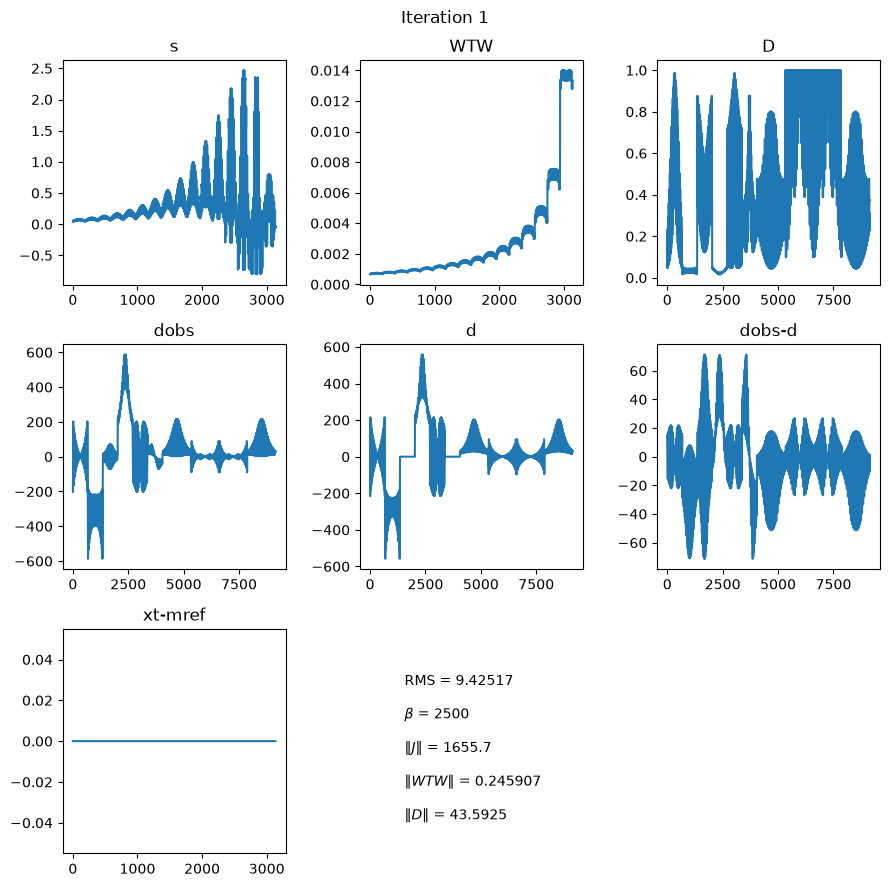

<Figure size 640x480 with 0 Axes>

done.
      err = 7.717392e-10, iter = 99
    Computing step length (parabolic line search)
      Forward modelling ... 

done.
      Forward modelling ... 

done.
  Computing regularization term
  ------------------------------------------------------------
  *** Iteration no 2 ***
    Forward modelling & computation of jacobian ... 

done.
    Weighted RMS: 1.86988, misfit: 0.0224984, smy: 895.774
    Computing perturbation with cglscd ... 

    Factorizing regularization matrix ... 

done.


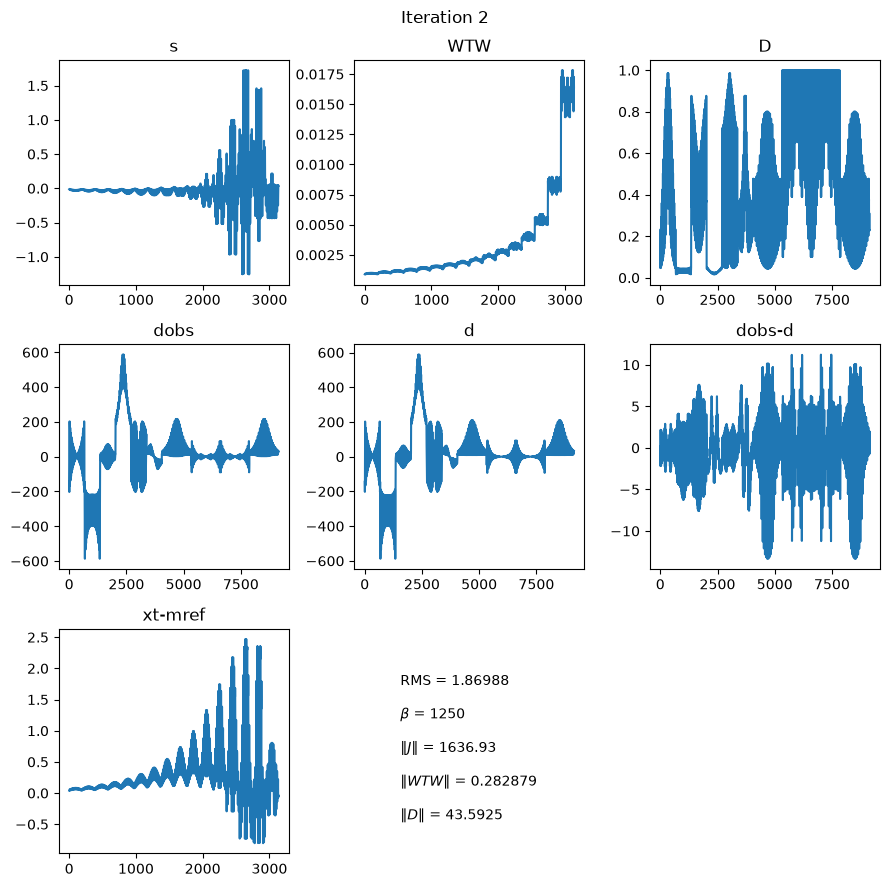

<Figure size 640x480 with 0 Axes>

done.
      err = 6.331105e-10, iter = 158
    Computing step length (parabolic line search)
      Forward modelling ... 

done.
      Forward modelling ... 

done.
  Computing regularization term
  ------------------------------------------------------------
  *** Iteration no 3 ***
    Forward modelling & computation of jacobian ... 

done.
    Weighted RMS: 0.840195, misfit: 0.0113707, smy: 220.772
    Computing perturbation with cglscd ... 

    Factorizing regularization matrix ... 

done.


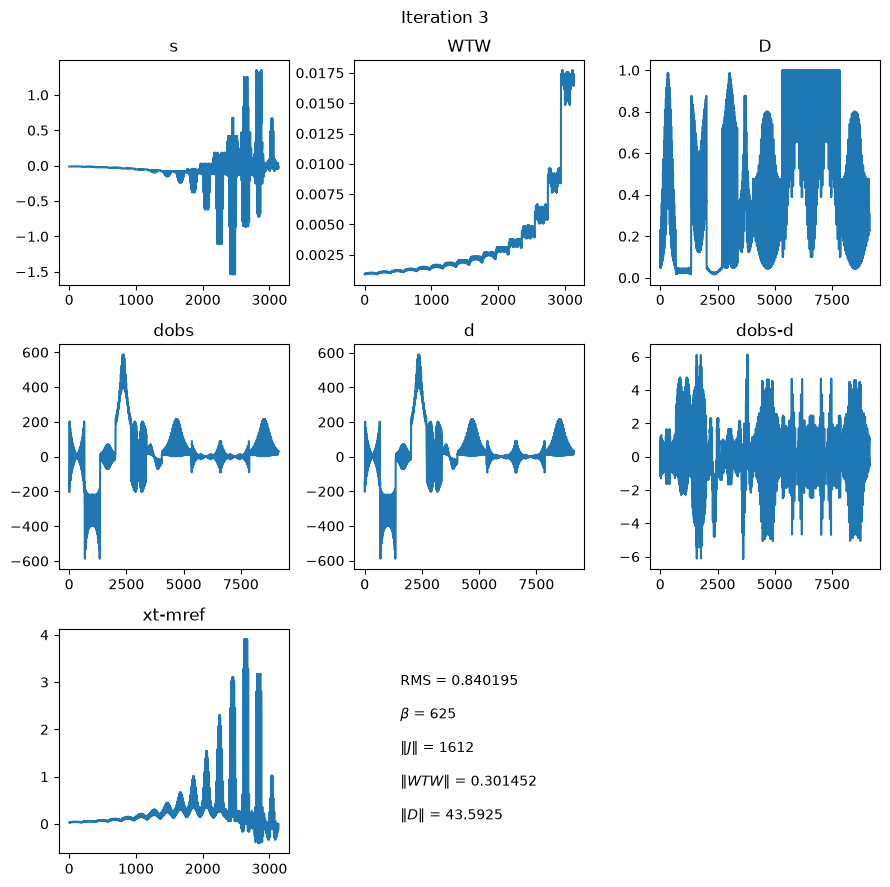

<Figure size 640x480 with 0 Axes>

done.
      err = 8.063469e-10, iter = 210
    Computing step length (parabolic line search)
      Forward modelling ... 

done.
      Forward modelling ... 

done.
  Computing regularization term
  ------------------------------------------------------------
  *** Iteration no 4 ***
    Forward modelling & computation of jacobian ... 

done.
    Weighted RMS: 0.436696, misfit: 0.00586393, smy: 171.283
    Computing perturbation with cglscd ... 

    Factorizing regularization matrix ... 

done.


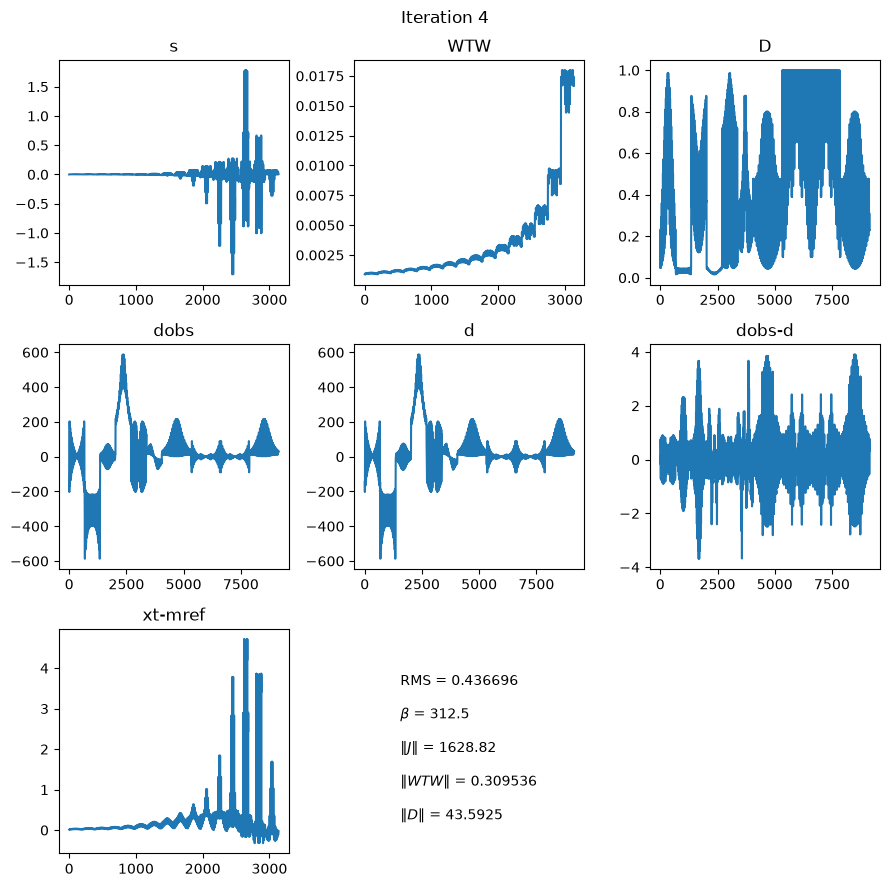

<Figure size 640x480 with 0 Axes>

done.
      err = 5.945609e-10, iter = 309
    Computing step length (parabolic line search)
      Forward modelling ... 

done.
      Forward modelling ... 

done.
  Computing regularization term
  ------------------------------------------------------------
  *** Iteration no 5 ***
    Forward modelling & computation of jacobian ... 

done.
    Weighted RMS: 0.393761, misfit: 0.00569706, smy: 113.444
    Computing perturbation with cglscd ... 

    Factorizing regularization matrix ... 

done.


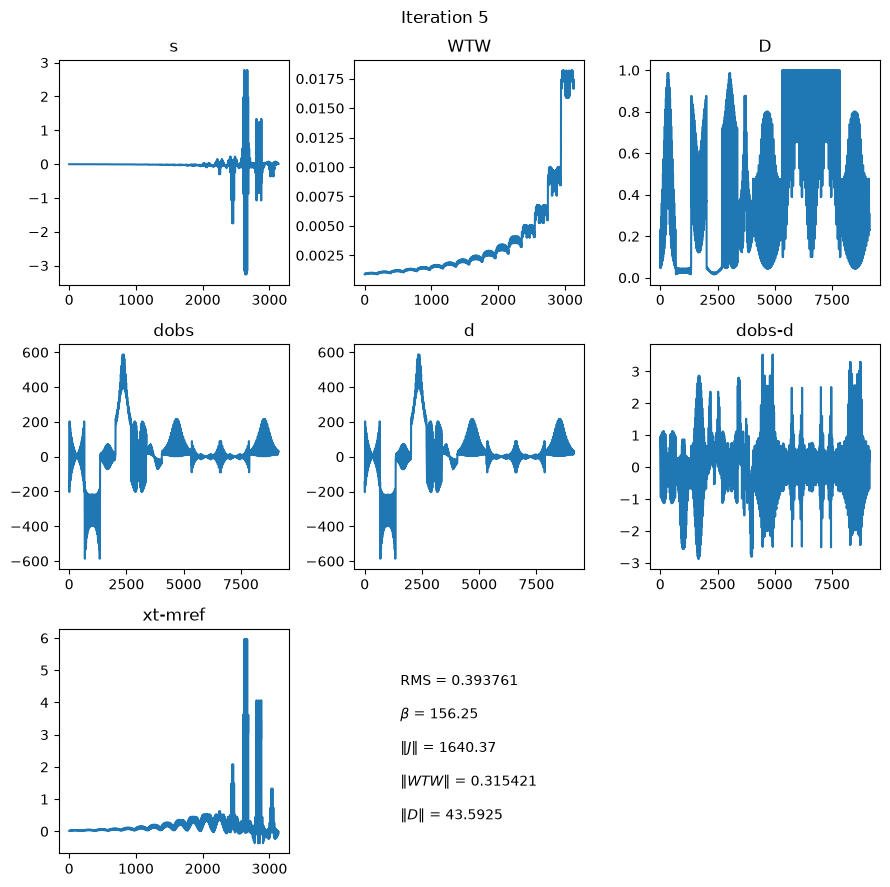

<Figure size 640x480 with 0 Axes>

done.
      err = 8.515028e-10, iter = 423
    Computing step length (parabolic line search)
      Forward modelling ... 

done.
      Forward modelling ... 

done.
  Computing regularization term
  ------------------------------------------------------------
End of inversion.


In [5]:
inv = Inversion()
inv.max_it = 5
inv.beta = 2500
inv.alx = 0.5
inv.aly = 0.5
inv.alz = 0.5
inv.beta_min = 100
inv.show_plots = True
inv.smooth_type = 'blocky'

m_ref = 0.001 + np.zeros((g.dc.nc,))

g.set_roi([-400, 400, -400, 400, -960, 0])

results = inv.run(g, data_mmr=data_mmr, m0=m_ref, m_ref=m_ref, data_ert=data_ert, m_active=g.ind_roi)

sigma_inv, data_inv, rms, misfit, smy = results

x, y, z = g.dc.get_roi_nodes()
g2 = GridFV((x, y, z))

fields = {}
for n, sigma in enumerate(sigma_inv):
    name = 'joint blocky - iteration {0:d}'.format(n+1)
    fields[name] = sigma

g2.toVTK(fields, 'example_joint_blocky')

## Misfit

Data misfit (RMSE weighted by the data errors, both data sets) at each iteration.

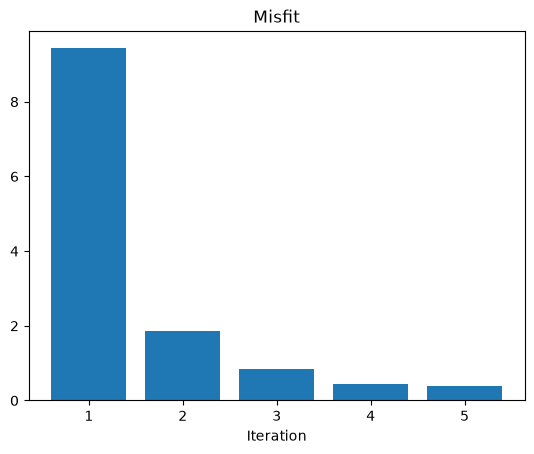

In [6]:
plt.figure()
plt.bar(np.arange(1, 1+len(rms)), rms)
plt.xlabel('Iteration')
plt.title('Misfit')
plt.show()